# Machine Learning Fundamentals
## Unit 01 — How Models Work, Data Exploration & Your First Model

**Stage 2**: Machine Learning
**Audience:** Beginner-level learners who completed the Python and data analysis foundations  
**Environment:** Google Colab / Jupyter Notebook  
**Core libraries:** Pandas, Matplotlib, Seaborn, scikit-learn

### Business scenario

You are a junior data scientist supporting a property analytics team. The team wants to estimate Melbourne house prices using selected property characteristics. Your first task is to understand the data, choose appropriate inputs, train a simple Decision Tree Regressor, and evaluate how well it predicts prices for properties it did not see during training.

### Dataset used

This notebook uses the **provided Melbourne housing dataset** (`melb_data.csv`), containing 13,580 records and 21 columns. The dataset includes property characteristics, location information, sale details, and sale price.





## Learning outcomes

By the end of this notebook, learners should be able to:

1. Explain how a Machine Learning model learns patterns from examples.
2. Describe the structure of a Decision Tree Regressor.
3. Inspect a real tabular dataset using Pandas.
4. Identify missing values and explain why they matter.
5. Distinguish model features (`X`) from the prediction target (`y`).
6. Follow the workflow: define, fit, predict, evaluate.
7. Make a prediction for a new property using the same feature structure.
8. Explain why evaluation must use data that was not used to fit the model.

## Notebook roadmap

1. How Models Work
2. Basic Data Exploration
3. Your First Machine Learning Model
4. First model evaluation
5. Practical activities, reflection, and readiness check

**How to use this notebook:** Read the Markdown explanation first, run the related code cell, inspect the output, and then complete the question or exercise before moving on.

# 1. How Models Work

## 1.1 What is a Machine Learning model?

Imagine a property analyst who has reviewed many past house sales. Over time, the analyst notices patterns: houses with more rooms may cost more, and location can be related to price. When a new house appears, the analyst uses these patterns to estimate its value.

A Machine Learning model follows a similar idea. It learns patterns from examples in historical data and uses those patterns to make predictions for new examples.

### Key terms

- **Observation / row:** One recorded property.
- **Feature:** An input used by the model, such as the number of rooms or the land size.
- **Target:** The value we want to predict. In this notebook, the target is `Price`.
- **Training:** Fitting a model to examples so it can learn patterns.
- **Prediction:** The model's estimated value for an input.
- **Evaluation:** Measuring how well predictions match known target values on data that was not used to train the model.

A model learns patterns from the data it receives. Those patterns may be incomplete or misleading, so model predictions should be checked before they are used to support decisions.

## 1.2 A first Decision Tree

A Decision Tree makes predictions by asking questions about input features. Each question creates a **split**. A property follows the branches that match its feature values until it reaches a **leaf**. For a regression tree, the leaf returns a numeric prediction.



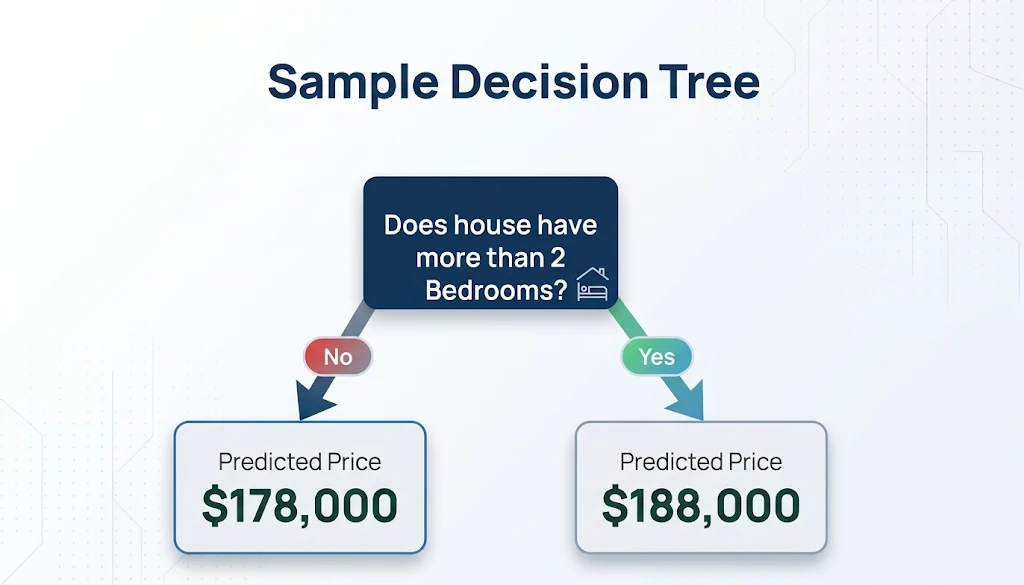

### How to read the tree

1. Start at the top node, called the root.
2. Answer the question using the property's feature value.
3. Follow the matching branch.
4. Read the prediction at the leaf.

A tree with one split is easy to explain, but it may ignore important factors. A deeper tree can use more conditions, but more complexity does not automatically mean better predictions on new data.

## 1.3 Comparing possible trees

Two trees can split the same dataset in different ways. We should not choose a tree only because its logic looks reasonable. We need to evaluate predictions using data that was not used to fit the model.

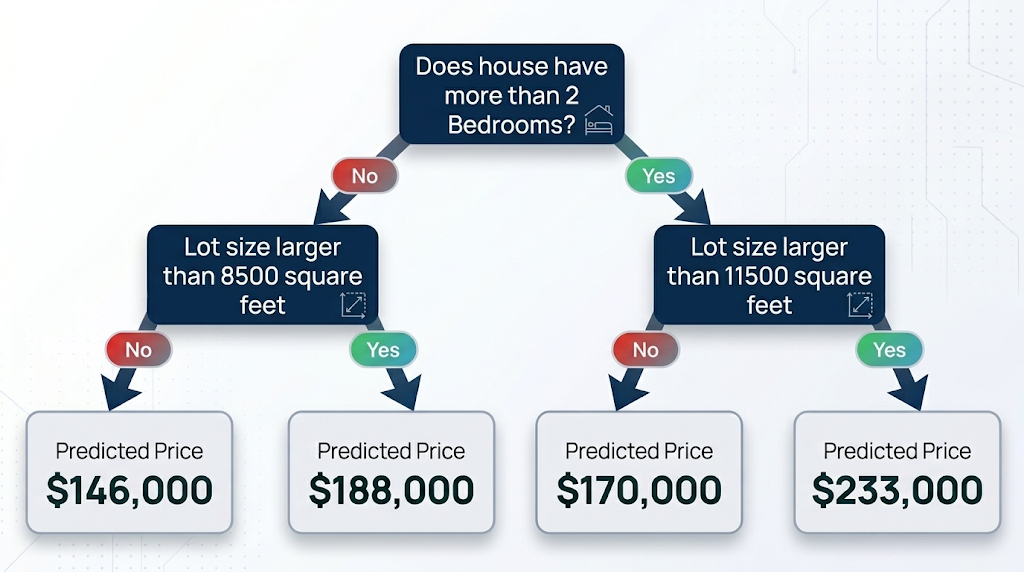

The first diagram illustrates that changing the split can change the prediction. A useful split should capture a pattern that helps predict the target, rather than merely creating more branches.

### A tree with more than one level

A tree can use more than one feature. For example, it may split first by number of bedrooms and then by lot size.

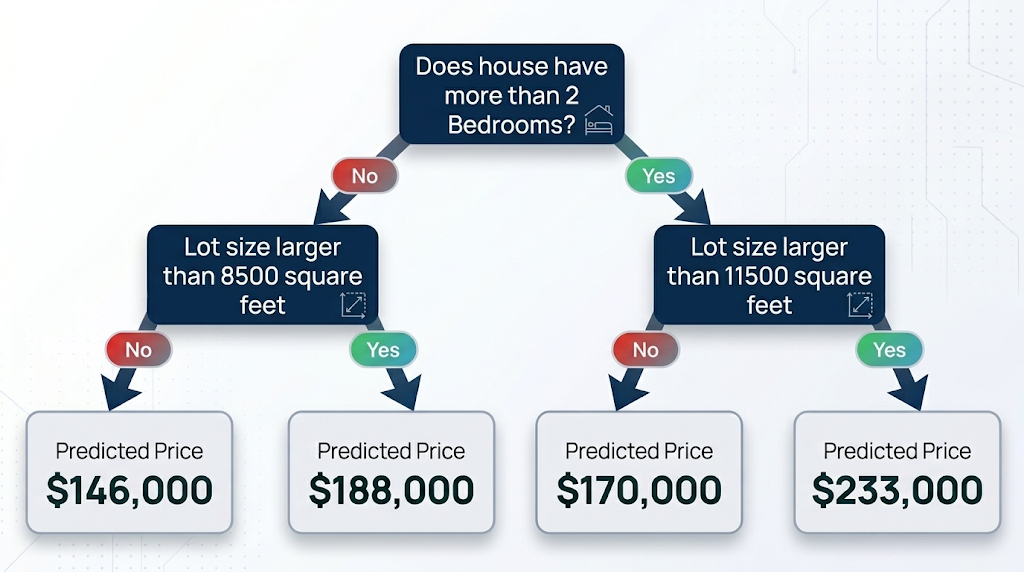

### Important teaching point

A Decision Tree can capture patterns and interactions between features, but it does not prove that a feature causes a price to change. This notebook focuses on prediction, not causal analysis.

### Check your understanding

Answer before continuing:

1. What is the difference between a feature and a target?
2. What does a leaf represent in a regression tree?
3. Why might a tree with more splits make better predictions?
4. Why is a deeper tree not automatically better?

# 2. Basic Data Exploration

## 2.1 Why explore data before modeling?

Before training a model, a data scientist needs to understand the dataset. Exploration helps answer questions such as:

- How many rows and columns are present?
- What does one row represent?
- Which columns are numeric, categorical, or date-related?
- Are values missing?
- Do any values look unusual?
- Which columns may be useful for the prediction task?

Pandas is commonly used to work with table-shaped data. A `DataFrame` is similar to a spreadsheet or a SQL table.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_absolute_error

# In Google Colab, upload melb_data.csv to the session first.
# If the file is in the same folder as this notebook, this path also works.
melbourne_file_path = "melb_data.csv"
melbourne_data = pd.read_csv(melbourne_file_path)

print("Dataset loaded successfully.")
print(f"Rows: {melbourne_data.shape[0]:,}")
print(f"Columns: {melbourne_data.shape[1]}")
display(melbourne_data.head())

Dataset loaded successfully.
Rows: 13,580
Columns: 21


,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,...,1.0,1.0,202.0,NaN,NaN,Yarra,-37.7996,144.9984,Northern Metropolitan,4019.0
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,...,1.0,0.0,156.0,79.0,1900.0,Yarra,-37.8079,144.9934,Northern Metropolitan,4019.0
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,...,2.0,0.0,134.0,150.0,1900.0,Yarra,-37.8093,144.9944,Northern Metropolitan,4019.0
3,Abbotsford,40 Federation La,3,h,850000.0,PI,Biggin,4/03/2017,2.5,3067.0,...,2.0,1.0,94.0,NaN,NaN,Yarra,-37.7969,144.9969,Northern Metropolitan,4019.0
4,Abbotsford,55a Park St,4,h,1600000.0,VB,Nelson,4/06/2016,2.5,3067.0,...,1.0,2.0,120.0,142.0,2014.0,Yarra,-37.8072,144.9941,Northern Metropolitan,4019.0


## 2.2 Understand the rows and columns

The `shape` property returns `(rows, columns)`. The `columns` property lists the column names. `dtypes` shows the data type stored in each column.

Use these outputs to understand what information is available before selecting features.

In [2]:
print("Dataset shape:", melbourne_data.shape)
print("\\nColumn names:")
print(melbourne_data.columns.tolist())

print("\\nData types:")
display(melbourne_data.dtypes.to_frame("data_type"))

Dataset shape: (13580, 21)
\nColumn names:
['Suburb', 'Address', 'Rooms', 'Type', 'Price', 'Method', 'SellerG', 'Date', 'Distance', 'Postcode', 'Bedroom2', 'Bathroom', 'Car', 'Landsize', 'BuildingArea', 'YearBuilt', 'CouncilArea', 'Lattitude', 'Longtitude', 'Regionname', 'Propertycount']
\nData types:


,data_type
Suburb,object
Address,object
Rooms,int64
Type,object
Price,float64
Method,object
SellerG,object
Date,object
Distance,float64
Postcode,float64


## 2.3 Summarize numeric columns with `describe()`

For numeric columns, `describe()` reports common summary statistics:

- **count:** Number of non-missing values.
- **mean:** Arithmetic average.
- **std:** Standard deviation, a measure of spread.
- **min / max:** Smallest and largest observed values.
- **25%, 50%, 75%:** Percentiles; the 50th percentile is the median.

These statistics help us understand typical ranges and notice possible anomalies. They do not explain why a pattern exists.

In [ ]:
display(melbourne_data.describe().T)

## 2.4 Inspect missing values

Missing values may occur because information was not recorded or did not apply to a property. In this dataset, `BuildingArea` and `YearBuilt` have many missing values.

Do not remove missing values automatically. First inspect which columns are affected and decide what is appropriate for the task. For this first model, we will use a small set of features and remove rows only when one of those selected features or the target is missing.

In [ ]:
missing_summary = pd.DataFrame({
    "missing_count": melbourne_data.isna().sum(),
    "missing_percent": (melbourne_data.isna().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)

display(missing_summary)

### Optional visualization — Missing values

A simple bar chart makes it easier to compare missing-value counts across columns.

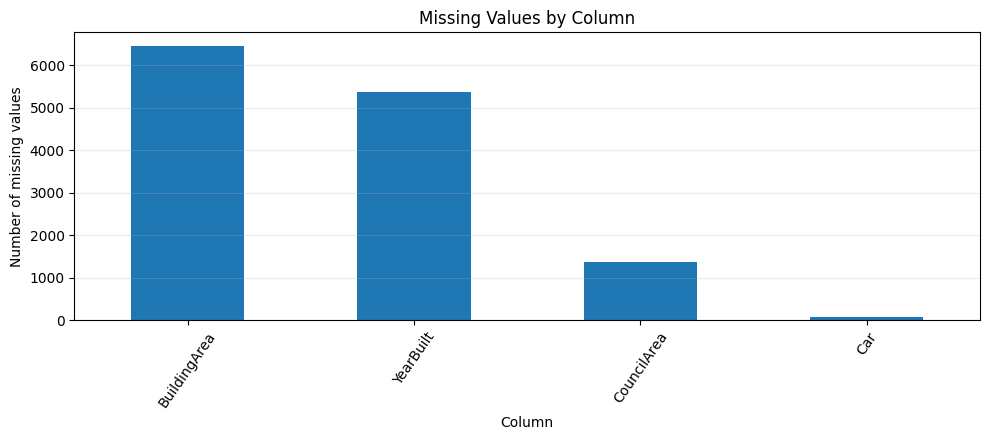

In [8]:
missing_counts = melbourne_data.isna().sum().sort_values(ascending=False)
missing_counts = missing_counts[missing_counts > 0]

fig, ax = plt.subplots(figsize=(10, 4.5))
missing_counts.plot(kind="bar", ax=ax)
ax.set_title("Missing Values by Column")
ax.set_xlabel("Column")
ax.set_ylabel("Number of missing values")
ax.tick_params(axis="x", rotation=55)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 2.5 Select the columns for our first model

The original dataset contains many variables. To keep the first model understandable, we will start with five numeric features:

- `Rooms`
- `Bathroom`
- `Landsize`
- `Lattitude`
- `Longtitude`

The target is `Price`.

This is a deliberate first selection, not a claim that these are the best possible features. Later lessons will show how to compare models and improve feature selection.

In [7]:
feature_names = ["Rooms", "Bathroom", "Landsize", "Lattitude", "Longtitude"]
target_name = "Price"

required_columns = feature_names + [target_name]
model_data = melbourne_data[required_columns].copy()

print("Selected columns:")
print(required_columns)
print("\\nRows before handling missing values:", len(model_data))
print("Missing values in selected columns:")
display(model_data.isna().sum().to_frame("missing_count"))

Selected columns:
['Rooms', 'Bathroom', 'Landsize', 'Lattitude', 'Longtitude', 'Price']
\nRows before handling missing values: 13580
Missing values in selected columns:


,missing_count
Rooms,0
Bathroom,0
Landsize,0
Lattitude,0
Longtitude,0
Price,0


## 2.6 Prepare a simple modeling table

For this first lesson, we will use the simplest approach: remove rows that have missing values in the selected features or target. This is called complete-case analysis.

**Limitation:** Removing rows can reduce the amount of data and may introduce bias if the missingness is systematic. We use it here to focus on the first model; missing-value strategies will be studied later.

In [9]:
model_data = model_data.dropna(subset=required_columns).copy()

print(f"Rows retained: {len(model_data):,}")
print(f"Rows removed: {len(melbourne_data) - len(model_data):,}")
print("Remaining missing values in selected columns:", int(model_data[required_columns].isna().sum().sum()))
display(model_data.head())

Rows retained: 13,580
Rows removed: 0
Remaining missing values in selected columns: 0


,Rooms,Bathroom,Landsize,Lattitude,Longtitude,Price
0,2,1.0,202.0,-37.7996,144.9984,1480000.0
1,2,1.0,156.0,-37.8079,144.9934,1035000.0
2,3,2.0,134.0,-37.8093,144.9944,1465000.0
3,3,2.0,94.0,-37.7969,144.9969,850000.0
4,4,1.0,120.0,-37.8072,144.9941,1600000.0


### Check your understanding — Basic Data Exploration

1. What does `DataFrame.shape` tell you?
2. What does `count` mean in `describe()`?
3. Why can the mean differ from the median?
4. Why is removing every row with any missing value not always a good strategy?
5. Why should we inspect the selected columns before training a model?

### Practical activity 2 — Basic Data Exploration

Complete the matching Kaggle lesson and exercise:

- [Kaggle: Basic Data Exploration](https://www.kaggle.com/code/yazeedalasmar/exercise-explore-your-data)

**Deliverable:** List three observations about the dataset and one question you would investigate before modeling.

# 3. Your First Machine Learning Model

## 3.1 Select the prediction target (`y`)

The **target** is the value we want the model to predict. By convention, it is often named `y`.

Here, `Price` is the target. Each value in `y` must correspond to the same property row as the matching row in `X`.

In [10]:
y = model_data[target_name]

print("Target:", y.name)
print("Target shape:", y.shape)
display(y.head())

Target: Price
Target shape: (13580,)


,Price
0,1480000.0
1,1035000.0
2,1465000.0
3,850000.0
4,1600000.0


## 3.2 Select the features (`X`)

**Features** are the input columns used to make predictions. By convention, the feature table is often named `X` (uppercase).

We select multiple columns by passing a list of column names to the DataFrame.

In [11]:
X = model_data[feature_names]

print("Feature table shape:", X.shape)
display(X.head())
display(X.describe().T)

Feature table shape: (13580, 5)


,Rooms,Bathroom,Landsize,Lattitude,Longtitude
0,2,1.0,202.0,-37.7996,144.9984
1,2,1.0,156.0,-37.8079,144.9934
2,3,2.0,134.0,-37.8093,144.9944
3,3,2.0,94.0,-37.7969,144.9969
4,4,1.0,120.0,-37.8072,144.9941


,count,mean,std,min,25%,50%,75%,max
Rooms,13580.0,2.937997,0.955748,1.00000,2.000000,3.000000,3.000000,10.00000
Bathroom,13580.0,1.534242,0.691712,0.00000,1.000000,1.000000,2.000000,8.00000
Landsize,13580.0,558.416127,3990.669241,0.00000,177.000000,440.000000,651.000000,433014.00000
Lattitude,13580.0,-37.809203,0.079260,-38.18255,-37.856822,-37.802355,-37.756400,-37.40853
Longtitude,13580.0,144.995216,0.103916,144.43181,144.929600,145.000100,145.058305,145.52635


### A useful distinction

- `X` contains the information the model receives.
- `y` contains the answer the model is learning to predict.
- `X` and `y` must contain the same number of rows in the same order.

## 3.3 Split the data before training

To estimate how well a model may perform on unseen properties, set aside a test set. The model must not learn from the test targets during training.

We use `train_test_split()` to create training and test data. The `random_state` setting makes the split reproducible.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Training feature shape:", X_train.shape)
print("Test feature shape:", X_test.shape)

Training rows: 10864
Test rows: 2716
Training feature shape: (10864, 5)
Test feature shape: (2716, 5)


## 3.4 Define and fit a Decision Tree Regressor

The basic workflow is:

1. **Define:** Choose the model type and settings.
2. **Fit:** Learn patterns from the training data.
3. **Predict:** Generate estimates for input rows.
4. **Evaluate:** Compare predictions with known target values on the test set.

We will use `DecisionTreeRegressor`, because the target `Price` is numeric. `max_depth=4` limits the tree's depth to keep this first model relatively simple. It is a teaching choice, not a claim that depth 4 is optimal.

In [14]:
melbourne_model = DecisionTreeRegressor(
    max_depth=4,
    random_state=1
)

melbourne_model.fit(X_train, y_train)

print("The Decision Tree Regressor has been fitted.")

The Decision Tree Regressor has been fitted.


## 3.5 Make predictions on the test set

The `predict()` method uses the fitted model to estimate prices. We will predict prices for the test rows, which were not used during fitting.

In [15]:
test_predictions = melbourne_model.predict(X_test)

prediction_comparison = pd.DataFrame({
    "Actual price": y_test,
    "Predicted price": test_predictions
})
prediction_comparison["Absolute error"] = (
    prediction_comparison["Actual price"] - prediction_comparison["Predicted price"]
).abs()

display(prediction_comparison.head(10).round(0))

,Actual price,Predicted price,Absolute error
1061,2600000.0,1302966.0,1297034.0
6482,620000.0,516793.0,103207.0
8395,1000000.0,1302966.0,302966.0
4659,430000.0,629870.0,199870.0
7386,392250.0,886179.0,493929.0
6607,700000.0,1102253.0,402253.0
8094,439000.0,516793.0,77793.0
4590,2236000.0,1302966.0,933034.0
13475,671000.0,629870.0,41130.0
10318,1870000.0,1302966.0,567034.0


## 3.6 Evaluate the model with MAE

**Mean Absolute Error (MAE)** is the average absolute difference between actual and predicted values.

For example, if MAE is `$100,000`, predictions are off by `$100,000` on average in absolute terms on this test set. MAE uses the same currency unit as the target.

MAE is easier to interpret than many technical metrics, but one score does not tell the whole story. It can vary with the test set, and it should be compared with a reasonable baseline.

In [17]:
mae = mean_absolute_error(y_test, test_predictions)
print(f"Test MAE: ${mae:,.0f}")

Test MAE: $305,783


## 3.7 Visualize actual versus predicted prices

A scatter plot compares each actual price with its predicted price. Points closer to the diagonal reference line indicate more accurate predictions.

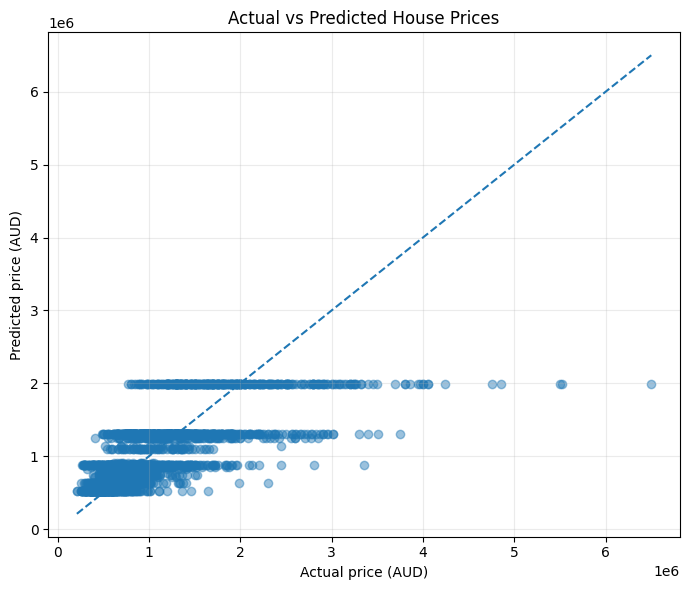

In [18]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_test, test_predictions, alpha=0.45)

lower = min(y_test.min(), test_predictions.min())
upper = max(y_test.max(), test_predictions.max())
ax.plot([lower, upper], [lower, upper], linestyle="--")

ax.set_title("Actual vs Predicted House Prices")
ax.set_xlabel("Actual price (AUD)")
ax.set_ylabel("Predicted price (AUD)")
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

## 3.8 Inspect the fitted tree

The tree visualization shows the questions the model learned from the training data. Each split uses a feature and a threshold; each leaf contains a predicted price.

The tree is limited to four levels to keep the diagram readable. Tree structure can change when the data, features, or settings change.

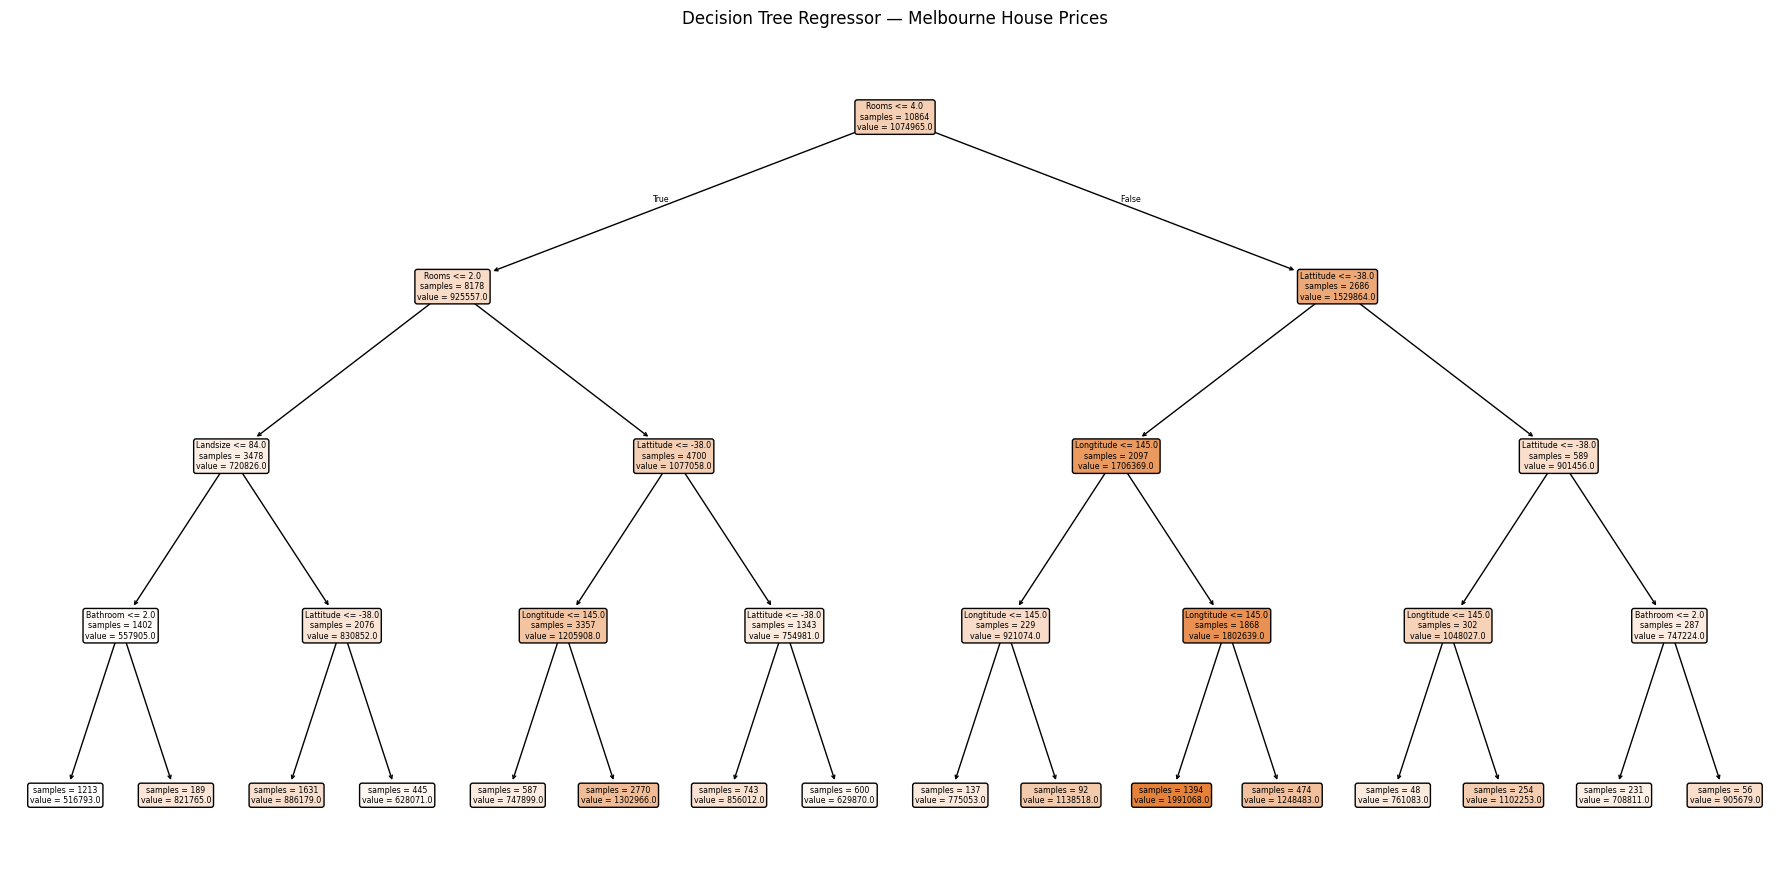

In [19]:
fig, ax = plt.subplots(figsize=(18, 9))
plot_tree(
    melbourne_model,
    feature_names=feature_names,
    filled=True,
    rounded=True,
    impurity=False,
    precision=0,
    ax=ax
)
ax.set_title("Decision Tree Regressor — Melbourne House Prices")
plt.tight_layout()
plt.show()

## 3.9 Predict a new property

A model can predict for a new property if the input contains the same features used during training. Feature names and column order should be kept consistent.

The values below are an illustrative example. The output is a model estimate, not an official property valuation.

In [20]:
new_property = pd.DataFrame([{
    "Rooms": 4,
    "Bathroom": 2.0,
    "Landsize": 500.0,
    "Lattitude": -37.81,
    "Longtitude": 144.99
}])

new_property = new_property[feature_names]
estimated_price = melbourne_model.predict(new_property)[0]

display(new_property)
print(f"Estimated price: ${estimated_price:,.0f} AUD")

,Rooms,Bathroom,Landsize,Lattitude,Longtitude
0,4,2.0,500.0,-37.81,144.99


Estimated price: $1,991,068 AUD


### Practical activity 3 — Your First Machine Learning Model

Complete the matching Kaggle lesson and exercise:

- [Kaggle: Your First Machine Learning Model](https://www.kaggle.com/code/yazeedalasmar/exercise-your-first-machine-learning-model)

**Deliverable:** Identify `X` and `y`, fit a Decision Tree Regressor, generate predictions, and explain what the test MAE tells you.

# 4. Reflection and readiness check

## Mini-challenge

Complete these tasks independently:

1. Change `max_depth` from 4 to 2 and then to 8.
2. Compare the test MAE for each version using the same train/test split.
3. Explain why a more complex tree may fit the training data well but perform poorly on new data.
4. Choose one additional numeric feature from the dataset and explain why it may be useful. Do not add it to the model without checking missing values and updating the feature list consistently.
5. Write a short conclusion with one observation, one limitation, and one next step.



In [21]:
depth_results = []

for depth in [2, 4, 8]:
    candidate_model = DecisionTreeRegressor(max_depth=depth, random_state=1)
    candidate_model.fit(X_train, y_train)
    candidate_predictions = candidate_model.predict(X_test)

    depth_results.append({
        "max_depth": depth,
        "test_MAE_AUD": mean_absolute_error(y_test, candidate_predictions)
    })

depth_comparison = pd.DataFrame(depth_results).sort_values("test_MAE_AUD")
display(depth_comparison)

,max_depth,test_MAE_AUD
2,8,247231.194150
1,4,305782.943023
0,2,369175.367633
